In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
url = 'https://github.com/s61711299-sketch/MSSP6070/raw/refs/heads/main/Assignment2/InternetSales.csv'
df = pd.read_csv(url,encoding='latin-1')
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns',None)

/tmp/ipykernel_2853/2963798050.py:7: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url,encoding='latin-1')


In [ ]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year

Q1.What are the Internet sales of Adventure Works by year for each Country Region?

In [ ]:
q1 = df.groupby(['Year', 'CountryRegionCode'])['SalesAmount'].sum().reset_index()
display(q1)
q1.to_csv('q1.csv', index=False)

,Year,CountryRegionCode,SalesAmount
0,2010,AU,2.090978e+04
1,2010,CA,3.578270e+03
2,2010,FR,3.399990e+03
3,2010,GB,6.990982e+02
4,2010,US,1.483390e+04
5,2011,AU,2.563732e+06
6,2011,CA,5.715718e+05
7,2011,DE,5.205002e+05
8,2011,FR,4.108453e+05
9,2011,GB,5.505912e+05


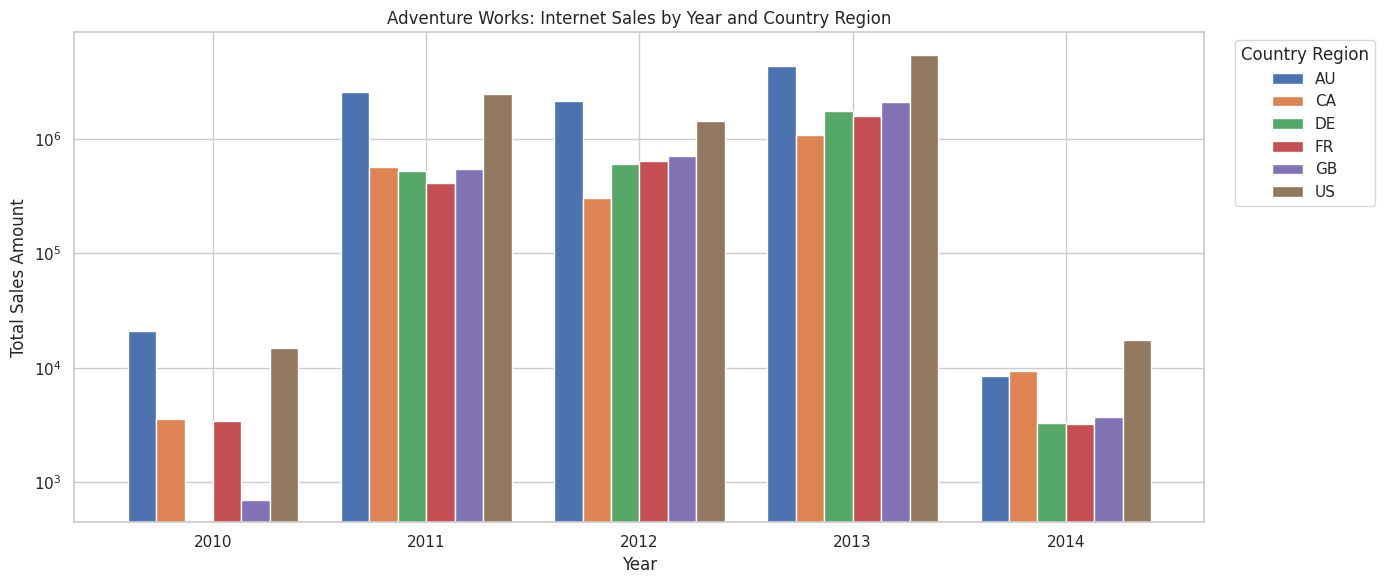

In [ ]:
q1_pivot = q1.pivot(
    index='Year',
    columns='CountryRegionCode',
    values='SalesAmount'
).fillna(0)
q1_pivot = q1_pivot.sort_index()
q1_pivot.index = q1_pivot.index.astype(str)
ax = q1_pivot.plot(
    kind='bar',
    figsize=(14, 6),
    width=0.8
)
ax.set_yscale('log')
plt.title('Adventure Works: Internet Sales by Year and Country Region')
plt.xlabel('Year')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=0)
plt.legend(title='Country Region', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

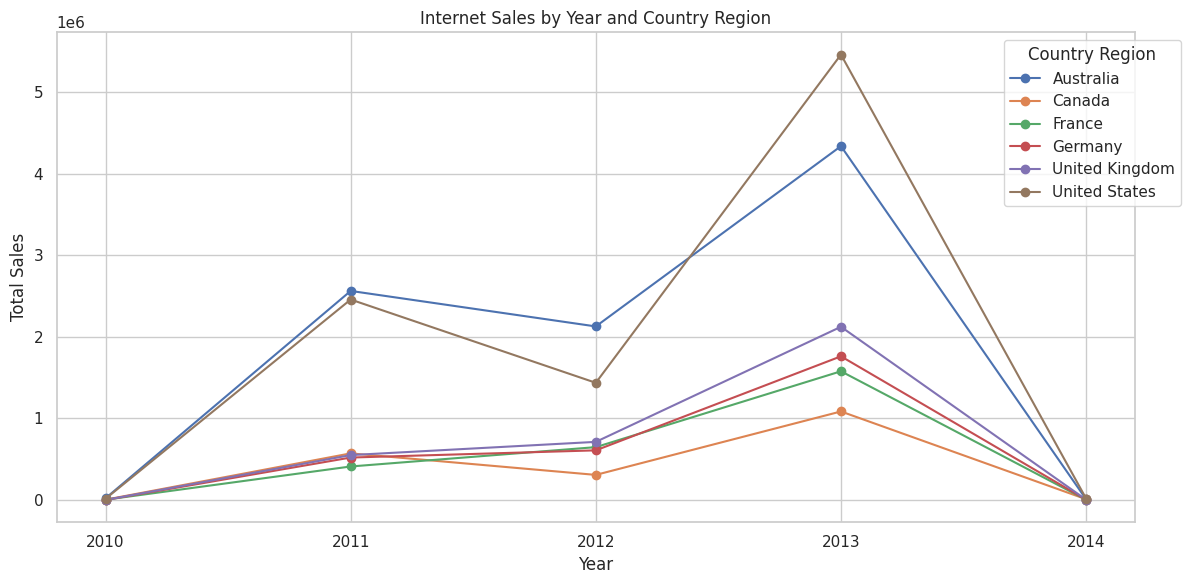

In [ ]:
sales_by_year_region = df.pivot_table(
    index='Year',
    columns='EnglishCountryRegionName',
    values='SalesAmount',
    aggfunc='sum',
    fill_value=0
)

sales_by_year_region.plot(
    kind='line',
    marker='o',
    figsize=(12, 6)
)

plt.title('Internet Sales by Year and Country Region')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.legend(title='Country Region', bbox_to_anchor=(1.05, 1))
plt.xticks([2010, 2011, 2012, 2013, 2014])
plt.tight_layout()
plt.show()

Q2.Generate summary statistics including min, max, and standard deviation for Yearly Income, Gender by Country Regions.

In [ ]:
income_by_gender = df.groupby(
    ['CountryRegionCode', 'Gender']
)['YearlyIncome'].agg(
    ['count', 'min', 'max', 'mean', 'std']
)

display(income_by_gender.round(2))
income_by_gender.to_csv('income_by_gender.csv', index=False)

count    min     max      mean       std
CountryRegionCode Gender                                          
AU                F        6685  10000  160000  67060.58  30613.96
                  M        6660  10000  170000  65412.91  32550.78
CA                F        3648  10000  170000  58651.32  19435.16
                  M        3972  10000  170000  61460.22  22702.85
DE                F        2820  10000  130000  48287.23  37622.81
                  M        2805  10000  130000  46730.84  37487.62
FR                F        2781  10000  110000  39367.13  28421.84
                  M        2777  10000  110000  39805.55  28665.66
GB                F        3401  10000  170000  56518.67  51130.69
                  M        3505  10000  170000  55771.75  50963.71
US                F       10682  10000  170000  64766.90  25498.81
                  M       10662  10000  170000  65450.20  26520.35

Q3.What is the average price of the product category that generates the most sales?

In [ ]:
top_category = df.groupby('EnglishProductName')['SalesAmount'].sum().idxmax()
print(f"The most sales: {top_category}")
avg_price = df[df['EnglishProductName'] == top_category]['UnitPrice'].mean()
print(f"Average price: {avg_price:.2f}")

The most sales: Mountain-200 Black, 46
Average price: 2215.27


In [ ]:
category_sales = (
    df.groupby('EnglishProductName')['SalesAmount']
      .sum()
      .sort_values(ascending=False)
)

display(category_sales)
top_category = category_sales.idxmax()
print("Top-selling category:", top_category)

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1.373470e+06
"Mountain-200 Black, 42",1.363142e+06
"Mountain-200 Silver, 38",1.339463e+06
"Mountain-200 Silver, 46",1.301100e+06
"Mountain-200 Black, 38",1.294866e+06
...,...
Touring Tire Tube,7.425120e+03
Patch Kit/8 Patches,7.307390e+03
Bike Wash - Dissolver,7.218600e+03


Top-selling category: Mountain-200 Black, 46


In [ ]:
df_to_download = category_sales.reset_index()
df_to_download.to_csv('Top_Selling_Products.csv', index=False, float_format='%.2f')
from google.colab import files
files.download('Top_Selling_Products.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Q4.Does owning a home make a difference in sales?

In [ ]:
print(df['HouseOwnerFlag'].value_counts(dropna=False))

home_sales = df.groupby('HouseOwnerFlag').agg(
    Total_Sales=('SalesAmount', 'sum'),
    Average_Sales=('SalesAmount', 'mean'),
    Sales_Records=('SalesAmount', 'count'),
    Unique_Customers=('CustomerKey', 'nunique')
)

home_sales.index = home_sales.index.map({
    1: 'Homeowner',
    0: 'Non-homeowner'
})

display(home_sales.round(2))

HouseOwnerFlag
1    41699
0    18699
Name: count, dtype: int64


,Total_Sales,Average_Sales,Sales_Records,Unique_Customers
HouseOwnerFlag,,,,
Non-homeowner,8973327.42,479.88,18699,5982
Homeowner,20385349.80,488.87,41699,12502


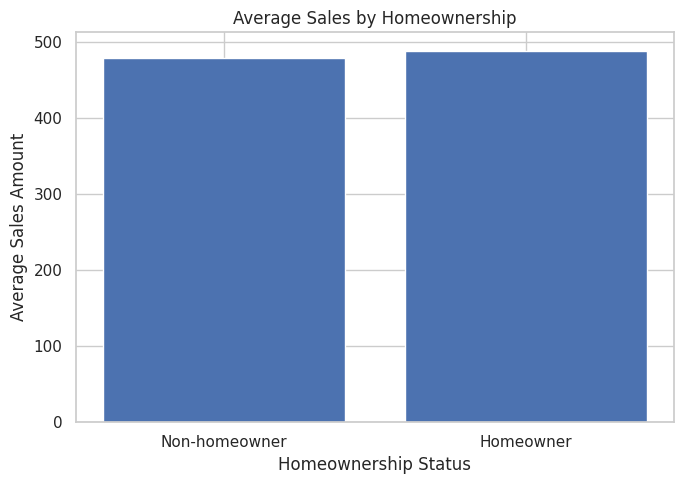

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    home_sales.index,
    home_sales['Average_Sales']
)

plt.title('Average Sales by Homeownership')
plt.xlabel('Homeownership Status')
plt.ylabel('Average Sales Amount')

plt.tight_layout()
plt.show()

In [ ]:
customer_sales = df.groupby(
    ['CustomerKey', 'HouseOwnerFlag']
)['SalesAmount'].sum().reset_index()

customer_home_sales = customer_sales.groupby(
    'HouseOwnerFlag'
)['SalesAmount'].agg(
    ['count', 'mean', 'median', 'std']
)

customer_home_sales.index = customer_home_sales.index.map({
    1: 'Homeowner',
    0: 'Non-homeowner'
})

display(customer_home_sales.round(2))

,count,mean,median,std
HouseOwnerFlag,,,,
Non-homeowner,5982,1500.05,209.96,2046.88
Homeowner,12502,1630.57,342.00,2159.07
